# 01 : Collecte des données (Tesla et Elon Musk)

Ce notebook télécharge toutes les données de la partie « Musk / Tesla » dans `data/` (dossier non versionné).
Il suffit de l'exécuter une fois : chaque fichier déjà présent est relu au lieu d'être retéléchargé.
Compter environ 15 minutes au premier lancement.

| Fichier | Contenu | Source |
|---|---|---|
| `musk_posts.parquet` | Tous les posts d'Elon Musk (2010-2025), heure recalculée depuis l'identifiant | Kaggle dadalyndell + Hugging Face fdaudens |
| `calendar.parquet` | Jours de bourse 2018-2024 avec heures d'ouverture et de fermeture | API Alpaca |
| `tsla_1min.parquet` | Barres à la minute de TSLA, heures étendues comprises (4 h - 20 h, New York) | API Alpaca (flux SIP) |
| `qqq_1min.parquet` | Barres à la minute de QQQ (Nasdaq-100), l'indice de référence | API Alpaca (flux SIP) |
| `daily_bars.parquet` | Barres journalières de TSLA, QQQ, SPY et DIA | API Alpaca |
| `tsla_news.parquet` | News Benzinga sur Tesla (titre et résumé), horodatées à la seconde | API Alpaca |
| `tsla_earnings.parquet` | Dates de publication des résultats de Tesla et EPS | Yahoo Finance (`yfinance`) |

Les clés API sont lues dans `.env` (voir `CLAUDE.md`).

In [1]:
import sys
from pathlib import Path

# Le notebook peut être lancé depuis la racine du projet ou depuis notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd

import collect
from collect import DATA

DATA.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 120)

START, END = "2018-01-01", "2024-12-31"
START_TS, END_TS = "2018-01-01T00:00:00Z", "2024-12-31T23:59:59Z"


def cached(name, fetch):
    """Relit data/<name> s'il existe, sinon le télécharge avec fetch() puis l'enregistre."""
    path = DATA / name
    if path.exists():
        return pd.read_parquet(path)
    df = fetch()
    df.to_parquet(path, index=False)
    return df

## 1. Posts d'Elon Musk

Aucun dataset n'est complet à lui seul : `dadalyndell` (Kaggle) sert de base et `fdaudens` (Hugging Face) ajoute
les posts manquants, surtout en 2023-2024. L'heure de chaque post est recalculée depuis son identifiant :
c'est plus fiable que les colonnes de date des fichiers (voir le rapport `reports/Datasets bourse et réseaux sociaux.md`).

Types de posts (`kind`) : `original`, `quote` (citation), `reply` (réponse), `retweet`.
Les posts venant de `fdaudens` ne distinguent pas les citations : elles sont comptées comme `original`.

In [2]:
posts = cached("musk_posts.parquet", collect.musk_posts)
posts["tesla"] = collect.mentions_tesla(posts["text"])
print(f"{len(posts):,} posts, du {posts.ts_utc.min():%Y-%m-%d} au {posts.ts_utc.max():%Y-%m-%d}")

period = posts[posts.ts_utc.dt.year.between(2018, 2024)]
pd.crosstab(period.ts_utc.dt.year, period.kind, margins=True)

78,807 posts, du 2010-11-04 au 2025-05-08


kind,original,quote,reply,retweet,All
ts_utc,,,,,
2018,513,91,1753,283,2640
2019,588,106,2246,361,3301
2020,646,61,2666,232,3605
2021,514,40,2564,164,3282
2022,801,110,4243,242,5396
2023,1121,456,11232,614,13423
2024,2325,3733,20317,2690,29065
All,6508,4597,45021,4586,60712


In [3]:
# Posts qui parlent de Tesla (filtre par mots-clés), hors retweets
tesla_posts = period[period.tesla & (period.kind != "retweet")]
pd.crosstab(tesla_posts.ts_utc.dt.year, tesla_posts.kind, margins=True)

kind,original,quote,reply,All
ts_utc,,,,
2018,109,24,333,466
2019,145,23,461,629
2020,86,9,305,400
2021,63,7,323,393
2022,48,10,236,294
2023,36,19,234,289
2024,48,97,278,423
All,535,189,2170,2894


## 2. Calendrier de bourse

Il donne les jours ouvrés et les séances écourtées (veilles de fêtes), pour savoir si un post tombe
pendant la séance, avant, après, ou marché fermé.

In [4]:
calendar = cached("calendar.parquet", lambda: collect.alpaca_calendar(START, END))
print(f"{len(calendar)} jours de bourse, dont {(calendar.close.dt.hour < 16).sum()} séances écourtées")
calendar.head()

1761 jours de bourse, dont 15 séances écourtées


,date,open,close
0,2018-01-02,2018-01-02 09:30:00,2018-01-02 16:00:00
1,2018-01-03,2018-01-03 09:30:00,2018-01-03 16:00:00
2,2018-01-04,2018-01-04 09:30:00,2018-01-04 16:00:00
3,2018-01-05,2018-01-05 09:30:00,2018-01-05 16:00:00
4,2018-01-08,2018-01-08 09:30:00,2018-01-08 16:00:00


## 3. Prix à la minute : TSLA et QQQ

Prix corrigés des divisions d'actions (`adjustment="split"`) : Tesla a divisé son action par 5 en août 2020
et par 3 en août 2022. Sans correction, ces dates ressembleraient à des krachs de -80 % et -67 %.
Chaque barre est étiquetée par **le début** de sa minute, en UTC. Une minute sans transaction n'a pas de barre.

In [5]:
tsla_1min = cached("tsla_1min.parquet", lambda: collect.alpaca_bars("TSLA", "1Min", START_TS, END_TS))
qqq_1min = cached("qqq_1min.parquet", lambda: collect.alpaca_bars("QQQ", "1Min", START_TS, END_TS))
for name, df in [("TSLA", tsla_1min), ("QQQ", qqq_1min)]:
    print(f"{name} : {len(df):,} barres, du {df.ts_utc.min():%Y-%m-%d} au {df.ts_utc.max():%Y-%m-%d}")

TSLA : 1,298,664 barres, du 2018-01-02 au 2024-12-31
QQQ : 1,402,722 barres, du 2018-01-02 au 2024-12-31


In [6]:
# Contrôle : le tweet « funding secured » (7 août 2018, 16:48:13 UTC)
window = tsla_1min[tsla_1min.ts_utc.between("2018-08-07 16:44", "2018-08-07 16:55")]
window[["ts_utc", "open", "high", "low", "close", "volume"]]

,ts_utc,open,high,low,close,volume
78613,2018-08-07 16:44:00+00:00,23.75,23.78,23.64,23.68,1487820
78614,2018-08-07 16:45:00+00:00,23.67,23.72,23.67,23.70,916335
78615,2018-08-07 16:46:00+00:00,23.70,23.81,23.70,23.80,2013750
78616,2018-08-07 16:47:00+00:00,23.80,23.83,23.76,23.79,1020735
78617,2018-08-07 16:48:00+00:00,23.78,24.58,23.77,24.24,15446835
78618,2018-08-07 16:49:00+00:00,24.25,24.74,24.22,24.74,10701045
78619,2018-08-07 16:50:00+00:00,24.74,24.74,24.07,24.12,7301070
78620,2018-08-07 16:51:00+00:00,24.12,24.21,23.94,24.04,6902865
78621,2018-08-07 16:52:00+00:00,24.05,24.27,24.00,24.23,3846360
78622,2018-08-07 16:53:00+00:00,24.24,24.25,23.80,23.95,4673625


## 4. Prix journaliers

Corrigés des divisions et des dividendes (`adjustment="all"`), pour les stratégies heuristiques
(moyennes mobiles, bandes de Bollinger) et la comparaison avec un placement passif.

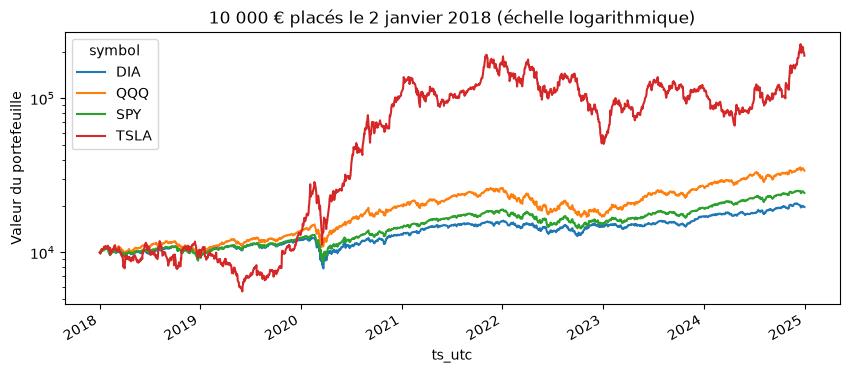

In [7]:
daily = cached("daily_bars.parquet", lambda: pd.concat(
    [collect.alpaca_bars(s, "1Day", START_TS, END_TS, adjustment="all") for s in ["TSLA", "QQQ", "SPY", "DIA"]],
    ignore_index=True))
closes = daily.pivot(index="ts_utc", columns="symbol", values="close")
(closes / closes.iloc[0] * 10_000).plot(logy=True, figsize=(10, 4),
                                       title="10 000 € placés le 2 janvier 2018 (échelle logarithmique)")
plt.ylabel("Valeur du portefeuille")
plt.show()

## 5. News Benzinga sur Tesla

Titres et résumés, horodatés à la seconde. Elles servent à repérer les autres événements qui font bouger
le cours au même moment qu'un post de Musk, et à tester FinBERT sur le type de texte pour lequel il a été entraîné.

In [8]:
news = cached("tsla_news.parquet", lambda: collect.alpaca_news("TSLA", START_TS, END_TS))
print(f"{len(news):,} news")
news.groupby(news.created_at.dt.year).size().rename("news par an")

28,432 news


created_at
2018    1688
2019    1534
2020    2844
2021    5426
2022    6573
2023    5359
2024    5008
Name: news par an, dtype: int64

## 6. Résultats trimestriels de Tesla

Les publications de résultats font fortement bouger l'action : il faudra les exclure des fenêtres d'événement
autour des posts. `yfinance` récupère les dates et l'EPS depuis Yahoo Finance, ce qui échoue parfois.

In [9]:
def fetch_earnings():
    import yfinance as yf
    df = yf.Ticker("TSLA").get_earnings_dates(limit=40).reset_index()
    df.columns = ["ts", "eps_estimate", "eps_reported", "surprise_pct"]
    return df


try:
    earnings = cached("tsla_earnings.parquet", fetch_earnings)
    in_period = earnings[earnings.ts.dt.year.between(2018, 2024)]
    print(f"{len(in_period)} publications de résultats sur 2018-2024")
    display(in_period.sort_values("ts").head())
except Exception as exc:
    print(f"Échec de yfinance ({exc}) : relancer plus tard ou trouver une autre source.")

28 publications de résultats sur 2018-2024


,ts,eps_estimate,eps_reported,surprise_pct
35,2018-02-07 16:00:00-05:00,-0.21,-0.20,3.44
34,2018-05-02 16:00:00-04:00,-0.24,-0.22,4.98
33,2018-08-01 16:00:00-04:00,-0.19,-0.20,-8.53
32,2018-10-24 16:00:00-04:00,NaN,0.19,12033.95
31,2019-01-30 16:00:00-05:00,0.14,0.13,-6.46


## 7. Bilan

In [10]:
for path in sorted(DATA.glob("*.parquet")):
    print(f"{path.name:28} {path.stat().st_size / 1e6:8.1f} Mo")

calendar.parquet                  0.0 Mo
daily_bars.parquet                0.3 Mo
finbert_musk_tesla.parquet        0.1 Mo
jev_musk_tesla.parquet            0.1 Mo
musk_posts.parquet                6.0 Mo
qqq_1min.parquet                 41.9 Mo
tsla_1min.parquet                34.0 Mo
tsla_earnings.parquet             0.0 Mo
tsla_news.parquet                 5.6 Mo
